# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
# importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv') #completa el código
usage = pd.read_csv('/datasets/usage.csv')#completa el código

In [3]:
plans.head() # mostrar las primeras 5 filas de plans

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
users.head()# mostrar las primeras 5 filas de users

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
usage.head()# mostrar las primeras 5 filas de usage

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
plans.info ()# inspección de plans con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
users.info() # inspección de users con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
usage.info() # inspección de usage con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print (users.isna().sum())  # Cantidad de valores nulos
print (users.isna().mean()) # Proporción de valores nulos

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [11]:
print (usage.isna().sum())
print (usage.isna().mean()) # cantidad de nulos para usage

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar
Diagnostico de valores nulos para Dataset users:
*city: Se identifican 469 valores nulos (11.73%). Se recomienda investigar su origen y conservarlos temporalmente sin imputar, para no asignar ciudades arbitrariamente que pudieran distorsionar el analisis geografico.
*churn_date: Presenta 3,534 valores nulos (88.35%). Aunque la proporcion es elevada, no se recomienda eliminar la columna porque contiene informacion esencial para analizar la cancelacion de los clientes. Se conservaran los valores nulos hasta confirmar si representan clientes activos o datos no registrados. No se recomienda imputar fechas artificiales.
*Resto de las columnas: No presentan valores nulos por lo que no requieren acciones de imputacion o eliminacion.
Diagnostico de valores nulos para Dataset usage:
*date: Presenta 50 valores nulos (.125%) Se recomienda evaluar su eliminacion, siempre que no sea necesaria para otro analisis, o dejar como nulos. No se recomienda imputar fechas artificiales.
*duration: Presenta 22,076 valores nulos (55.19%) Se recomienda conservar la columna y verificar si los valores faltantes corresponden a registros de mensajes, para los cuales la duracion no aplica.
*length: Presenta 17,896 valores nulos (44.74%). Se recomienda conservar la columna y verificar si los valores faltantes corresponden a llamadas, para las cuales la longitud no aplica.
*Resto de las columnas: No presentan valores nulos y no requieren acciones de imputacion o eliminacion.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
users.describe () # explorar columnas numéricas de users

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` ... Haz doble clic en este bloque y escribe qué ves.
  *La columna de user_id tiene 4000 registros. La identificacion de los mismos empieza en el 10,000 y termina en el 13,999. Al parecer todos los ids, son consecutivos, y no parece haber valores invalidos.
- La columna `age`
   *La columna age presenta un valor minimo sospechoso de -999, que no corresponde a una edad valida y podria representar un sentinel utilizado para indicar datos faltantes. La desviacion estandar es muy alta (123.23), lo que tambien sugiere que este valor afecta la distribucion estadistica. El valor minimo de -999 impide identificar directamente la edad minima valida a partir de este resumen estadistico. El primer cuartil se encuentra en 32 años y la edad maxima es de 79 años.

In [13]:
usage.describe()# explorar columnas numéricas de usage

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id`...Haz doble clic en este bloque y escribe qué ves.
  * Las columnas 'id' y 'user_id' presentan la misma cantidad de registros (40,000). En ninguna se observan valores atipicos o sospechosos evidentes
- Las columnas 'duration' y 'length'
  * Las columnas 'duration' y 'length' si presentan ciertas anomalias:
  * 'duration' contiene 17,924 valores registrados y 22076 valores faltantes. Presenta un valor maximo de 120, muy superior a la mediana de 3.5, lo que podria indicar la presencia de valores atipicos.
  * 'length' contiene 22,104 valores registrados y 17,896 valores faltantes. Su valor maximo de 1490, es muy superior a la mediana de 50, lo que tambien podria indicar presencia de valores atipicos. Ambas columnas requieren una revision adicional para determinar si estos valores extremos son validos o representan anomalias.

In [14]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
for columna in columnas_user:
    print(users[columna].value_counts())


Bogotá      808
CDMX        730
Medellín    616
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64
Basico     2595
Premium    1405
Name: plan, dtype: int64


- La columna `city` contiene 6 ciudades diferentes: Bogota, CDMX, Medellin, GDL, Cali, MTY, pero tambien presenta 96 registros con el valor '?', que podria representar un valor centinela para indicar informacion faltante o desconocida
- La columna `plan` contiene dos categorias: Basico(2,595 registros) y Premium (1,405 registros). No se identifican valores sospechosos en esta columna

In [15]:
# explorar columna categórica de usage
usage['type'].value_counts() # completa el código

text    22092
call    17908
Name: type, dtype: int64

- La columna `type` contiene dos categorias: text con 22092 registros y call con 17908 registros. Ambas categorias representan valores validos y no se identifican valores sospechosos ni posibles sentinels.


### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce') # completa el código

In [17]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')# completa el código

In [18]:
users['reg_date'].dt.year.value_counts().sort_index()# Revisar los años presentes en `reg_date` de users


2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64

En `reg_date`, se encontraron 40 registros del año 2026, fuera del rango esperado (hasta 2024). Se deben revisar para determinar si son errores de captura y corregirlos si es posible. De lo contrario, sustituirlos por NaT

In [19]:
usage['date'].dt.year.value_counts().sort_index() # Revisar los años presentes en `date` de usage


2024.0    39950
Name: date, dtype: int64

En `date`, ... la columna date contiene 39,950 registros correspondientes al año 2024. No se identificaron fechas con años fuera del rango esperado.  
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:
*Dataset users:
columna reg_date: Se identificaron 40 registros correspondientes al año 2026, fuera del rango esperado. Revisar las fechas para identificar posibles errores de captura. Si es posible, recuperar la fecha correcta. Si no, sustituirla por NaT.
*Dataset usage:
columna date: Se identificaron 39,950 registros correspondientes al año 2024. No se encontraron años fuera de rango esperado. No hay que modificar las fechas identificadas en esta columna. Sin embargo, los 50 registros faltantes, de los 40,000 identificados, deben considerarse pendientes de revision ya que no aparecen en el conteo de años. 

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [20]:
# Reemplazar -999 por la mediana de age
age_mediana = users['age'].replace(-999, float('nan')).median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [21]:
users['city'] = users['city'].replace('?', pd.NA) # Reemplazar ? por NA en city
users['city'].value_counts(dropna=False)

# Verificar cambios


Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64

In [22]:
users['reg_date']=pd.to_datetime(users['reg_date'], errors='coerce')
users['reg_date']=users['reg_date'].where(users['reg_date'].dt.year<=2024, pd.NaT)

users['reg_date'].dt.year.value_counts().sort_index() # Verificar cambios


2022.0    1314
2023.0    1316
2024.0    1330
Name: reg_date, dtype: int64

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [23]:
usage.groupby('type')['duration'].apply(lambda x: x.isna().sum()) # Verificación MAR en usage (Missing At Random) para duration


type
call        0
text    22076
Name: duration, dtype: int64

In [24]:
usage.groupby('type')['length'].apply(lambda x:x.isna().sum())# Verificación MAR en usage (Missing At Random) para length


type
call    17896
text        0
Name: length, dtype: int64

Los valores nulos en duration y length dependen de la variable type. La duracion no aplica para los mensajes y la longitud no aplica para las llamadas. Por lo tanto, se consideran MAR y se conservan como valores nulos, ya que representan datos no aplicables y no errores de captura o datos faltantes.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [25]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby('user_id')[['is_text', 'is_call', 'duration']].sum().reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [26]:
usage_agg.columns = ['user_id','cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']# Renombrar columnas

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [27]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on='user_id', how='left')
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [28]:
user_profile.describe() # Resumen estadístico de las columnas numéricas


,user_id,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,3999.000000,3999.000000,3999.000000
mean,11999.500000,48.136000,5.524381,4.478120,23.317054
std,1154.844867,17.689919,2.358416,2.144238,18.168095
min,10000.000000,18.000000,0.000000,0.000000,0.000000
25%,10999.750000,33.000000,4.000000,3.000000,11.120000
50%,11999.500000,48.000000,5.000000,4.000000,19.780000
75%,12999.250000,63.000000,7.000000,6.000000,31.415000
max,13999.000000,79.000000,17.000000,15.000000,155.690000


In [29]:
user_profile['plan'].value_counts(normalize=True) *100 # Distribución porcentual del tipo de plan


Basico     64.875
Premium    35.125
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

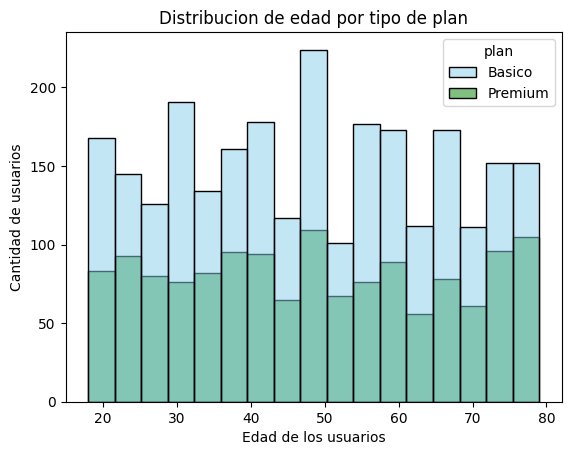

In [30]:
# Histograma para visualizar la edad (age)
sns.histplot(
    data=user_profile,
    x='age',
    hue='plan',
    palette=['skyblue', 'green']
)
plt.title('Distribucion de edad por tipo de plan')
plt.xlabel('Edad de los usuarios')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: 
- Distribución por edad: La distribucion por edades es similar para ambos planes, con usuarios distribuidos a lo largo de todo el rango de edad. Sin embargo, se observa un ligero incremento de usuarios Premium alrededor de los 50 años. En el plan basico, tambien se observa un pico en ese rango de edad, aunque con frecuencia mayor. En general, no se aprecia una diferencia marcada en la distribucion de edades entre ambos planes. La distribucion por edades es bastante simetrica.

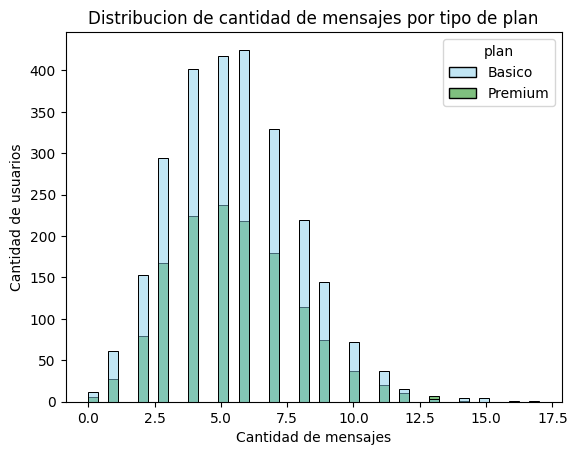

In [31]:
# Histograma para visualizar la cant_mensajes
sns.histplot(
    data=user_profile,
    x='cant_mensajes',
    hue='plan',
    palette=['skyblue', 'green']
)
plt.title('Distribucion de cantidad de mensajes por tipo de plan')
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Cantidad de usuarios')
plt.show()


💡Insights: 
- La distribucion muestra un sesgo a la derecha. La mayor concentracion de usuarios para ambos planes se encuentra alrededor de los 5 mensajes. A medida que aumenta la cantidad de mensajes enviados, la frecuencia de usuarios disminuye progresivamente, por lo que son pocos los clientes que registran un volumen elevado de mensajes.

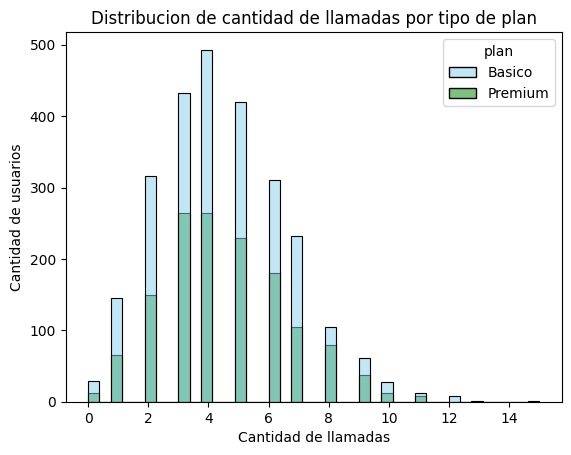

In [32]:
# Histograma para visualizar la cant_llamadas
sns.histplot(
    data=user_profile,
    x='cant_llamadas',
    hue='plan',
    palette=['skyblue', 'green']
)
plt.title('Distribucion de cantidad de llamadas por tipo de plan')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Cantidad de usuarios')
plt.show()


💡Insights: 
- La distribución presenta un sesgo hacia la derecha, con una mayor concentracion de usuarios alrededor de las 4 llamadas. La mayoria de los usuarios registra entre 2 y 8 llamadas, mientras que la frecuencia disminuye considerablemente a partir de las 8. Ambos planes muestran patrones generales similares, aunque se observan ligeras diferencias en la participacion de cada plan en determinados intervalos.

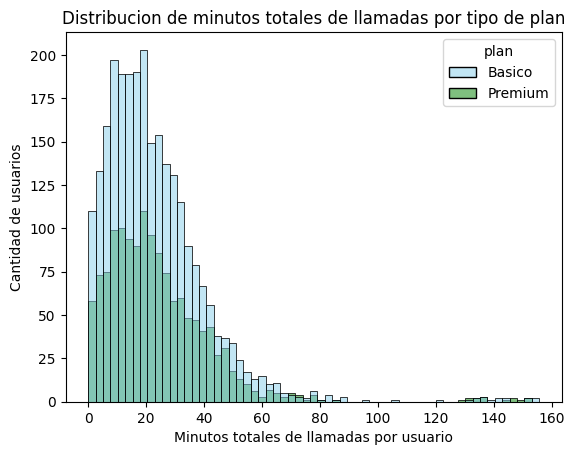

In [33]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(
    data=user_profile,
    x='cant_minutos_llamada',
    hue='plan',
    palette=['skyblue', 'green']
)
plt.title('Distribucion de minutos totales de llamadas por tipo de plan')
plt.xlabel('Minutos totales de llamadas por usuario')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: 
- La distribucion presenta un claro sesgo a la derecha en ambos planes. La mayoria de los usuarios acumula entre 5 y 30 minutos totales de llamadas durante el periodo analizado, mientras que un numero reducido registra consumos considerablemente mayores. Ambos planes muestras patrones generales similares, aunque se observan posibles valores atipicos asociados a usuarios con un volumen excepcionalmente alto de minutos acumulados.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

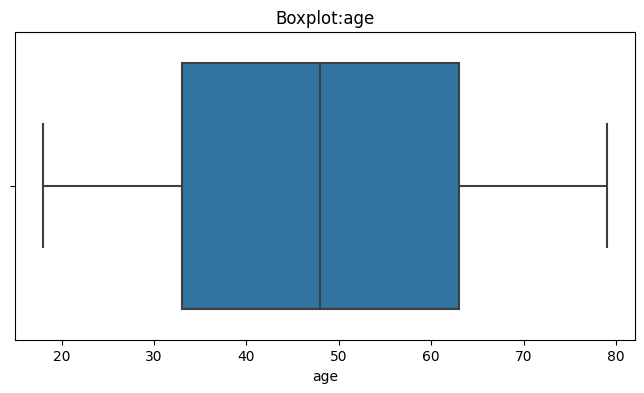

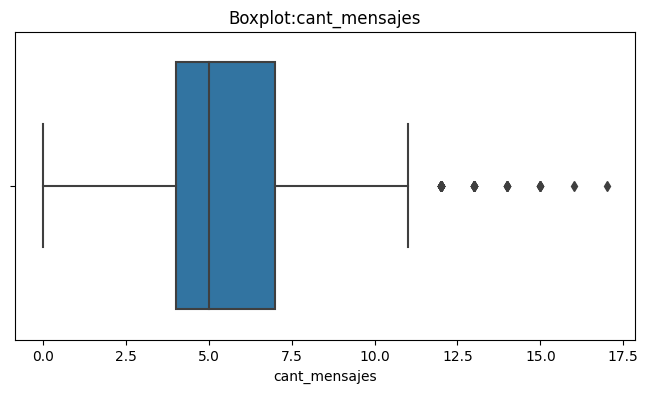

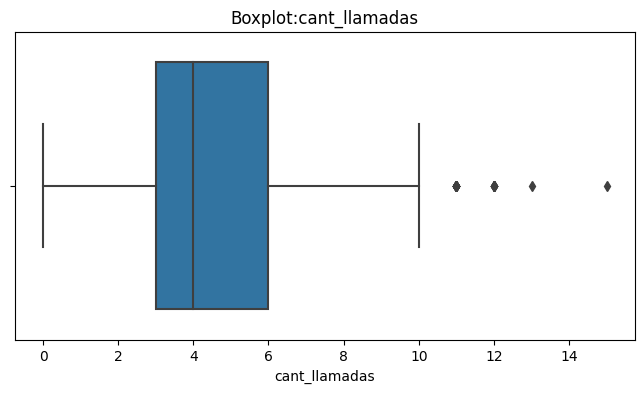

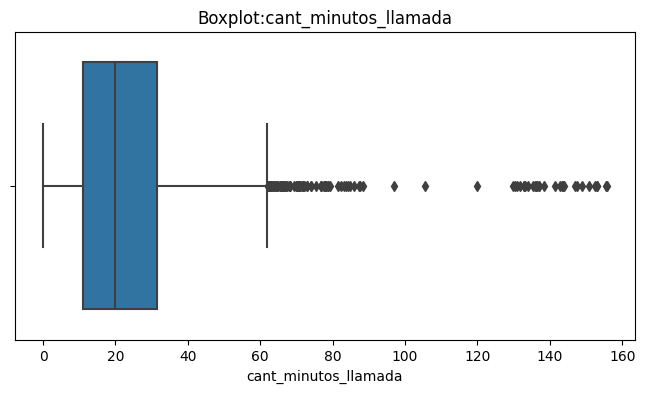

In [34]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(8,4))
    sns.boxplot(data=user_profile, x=col)
    plt.title(f'Boxplot:{col}')
    plt.show()

💡Insights: 
- Age: No presenta outliers. Los datos se encuentran dentro de los limites de los bigotes del boxplot
- cant_mensajes: Se identifican valores atipicos en el extremo superior, correspondientes a usuarios que registran una cantidad de mensajes mayor que la mayoria.
- cant_llamadas: Se identifican algunos valores atipicos en el extremo superior, indicando que algunos usuarios realizan mas llamadas que el resto.
- cant_minutos_llamada: Se identifica una cantidad considerable de valores atipicos en el extremo superior, lo que evidencia una dispersion importante entre los usuarios con mayor consumo de minutos.

In [35]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
for col in columnas_limites:
    Q1= user_profile[col].quantile(0.25)
    Q3= user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_superior = Q3 + 1.5 * IQR
    print(f'{col}: {limite_superior}')



cant_mensajes: 11.5
cant_llamadas: 10.5
cant_minutos_llamada: 61.8575


In [36]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué? Mantener outliers: El valor maximo alcanza 17 mensajes, superando el limite superior de 11.5. Se conservan porque representan niveles de actividad posibles de los usuarios y no hay evidencia de errores en los datos.
- cant_llamadas: mantener o no outliers, porqué? Mantener outliers: Se registran hasta 15 llamadas, lo cual esta por encima del limite superior de 10.5, sin embargo pueden corresponder a usuarios que realizan un mayor numero de llamadas y no necesariamente son errores, por lo tanto se conservan.
- cant_minutos_llamada: mantener o no outliers, porqué? Mantener outliers: Aunque el valor maximo de 155.69 minutos supera por mucho el limite superior de 61.86, se conservan porque pueden representar usuarios con un consumo intensivo de llamadas y no tenemos evidencia de que sean datos incorrectos.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [37]:
# Crear columna grupo_uso
condiciones = [
    (user_profile['cant_llamadas'].fillna(0)<5) & (user_profile['cant_mensajes'].fillna(0) <5),
    (user_profile['cant_llamadas'].fillna(0) <10)& (user_profile['cant_mensajes'].fillna(0) <10)
]
categorias = ['Bajo uso', 'Uso medio']
user_profile['grupo_uso'] = np.select(condiciones, categorias, default = 'Alto uso')

In [38]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [39]:
# Crear columna grupo_edad
condiciones = [
    user_profile['age'] < 30,
    user_profile['age'] < 60
]
categorias = ['Joven', 'Adulto']
user_profile['grupo_edad'] = np.select(condiciones, categorias, default='Adulto mayor')

In [40]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

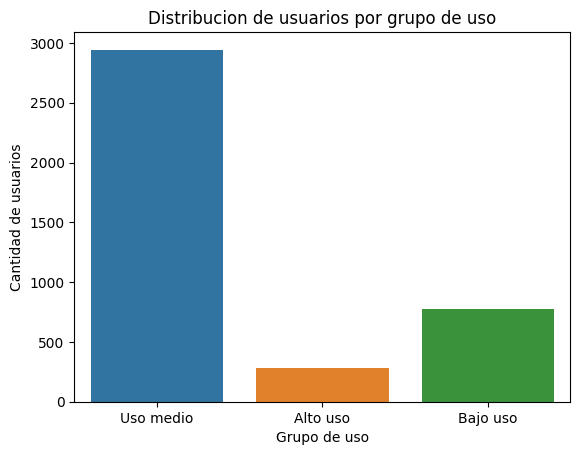

In [41]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso')
plt.title('Distribucion de usuarios por grupo de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')

plt.show()

In [42]:
user_profile['grupo_uso'].value_counts()

Uso medio    2943
Bajo uso      779
Alto uso      278
Name: grupo_uso, dtype: int64

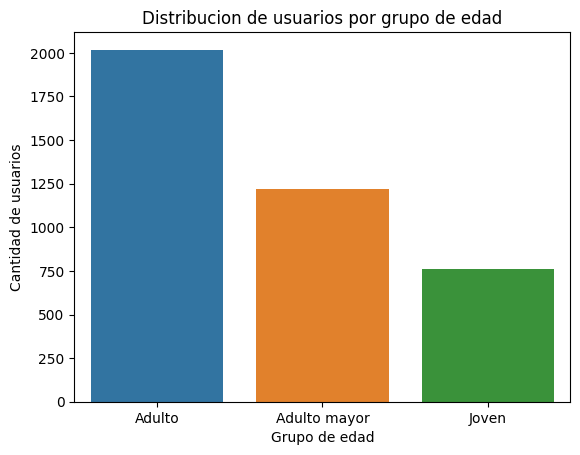

In [43]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad')
plt.title('Distribucion de usuarios por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de usuarios')

plt.show()


In [44]:
user_profile['grupo_edad'].value_counts()

Adulto          2018
Adulto mayor    1222
Joven            760
Name: grupo_edad, dtype: int64


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- Edades invalidas: Se identificaron 55 registros con el valor -999(1.38%). Se sustituyeron por la mediana de 48 años.
- Ciudades faltantes: Se encontraron 469 valores nulos y 96 registros con el simbolo '?', equivalentes en conjunto al 14.13% de los usuarios. Se conservaron como valores faltantes.
- Fechas inconsistentes: Se detectaron 40 fechas de registro fuera del periodo esperado(1%) y 50 fechas faltantes en usage (.13%). Las fechas invalidas se trataron como valores nulos.
- Datos de llamadas y mensajes: Se identificaron 22,076 valores nulos en duration (55.19%) y 17,896 en length (44.74%). Se comprobo que corresponden a campos no aplicables segun el tipo de actividad, por lo que se conservaron sin modificaciones.


🔍 **Segmentos por Edad**
- Adultos (30 a 59 años): 2,018 usuarios(50.45%). Representan el segmento mas numeroso de ConnectaTel.
- Adultos mayores (60 años o mas): 1,222 usuarios (30.55%). Constituyen el segundo grupo mas importante.
- Jovenes (menores de 30 años): 760 usuarios (19%). Son el segmento con menor participacion.
- Hallazgo principal: el 81% de los clientes tiene 30 años o mas. Sin embargo, las distribuciones de edad entre los planes Basico y Premium son similares, por lo que no se observa una diferencia marcada en la eleccion del plan segun la edad.


📊 **Segmentos por Nivel de Uso**
- Uso medio: 2,943 usuarios (73.58%). Es el segmento predominante, con un consumo moderado de llamadas y mensajes.
- Bajo uso: 779 usuarios (19.48%). Representan una oportunidad para ofrecer planes economicos ajustados a sus necesidades.
- Alto uso: 278 usuarios (6.95%). Aunque son una minoria, podrian representar una oportunidad comercial para planes con mayores beneficios de comunicacion.
- Patrones de consumo extremo: Se identificaron valores atipicos de hasta 17 mensajes, 15 llamadas y 155.69 minutos acumulados. Estos registros se conservaron porque no existe evidencia de errores y podrian representar usuarios con necesidades de comunicacion superiores al promedio.
- Hallazgo principal: La mayoria de los clientes presenta un nivel de uso medio. Esto sugiere que ConnectaTel deberia priorizar ofertas para este segmento, sin descuidar las necesidades de los usuarios de bajo y alto consumo.
  

💡 **Recomendaciones**
- Optimizar los planes actuales: Evaluar si los beneficios de los planes Basico y Premium se ajustan al patron de consumo del segmento de uso medio (73.58%) de los clientes, identificando posibles oportunidades de mejora.
- Crear un plan economico: Evaluar una opcion de menor costo para los usuarios de bajo uso (19.48%), con el objetivo de ofrecer beneficios acordes a sus necesidades y favorecer su permanencia.
- Personalizar ofertas: Utilizar los patrones de consumo como criterio principal de segmentacion complementandolos con la edad para poder ofrecer planes mas especificos.
- Segmentos con potencial comercial: Los usuarios de alto consumo (6.95%) podrian representar una oportunidad para ofrecer planes de mayor capacidad. Sin embargo, se requiere analizar sus ingresos y costos antes de considerarlos como los clientes mas rentables.
- Validar rentabilidad: Analizar ingresos, costos y permanencia de cada segmento antes de implementar nuevos planes o modificar precios.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`